### Test notebook for CHAZ retraining

Steps: 
1. get calCoefficient_water_guess running in this notebook
2. run on ERA5 data from 1981 to 2012
3. compare results to input data 
4. run on ERA data from 1981 to 2024
    or run on ERA data from 1950 to 2024? 
    maybe both see how they are different
5. if that all looks good, turn into .py that can be run programatically 

In [7]:
### TEMPORARY (hopefully) code snippet so that the HTML view of datasets/dataarrays is viewable in darkmode on jupyter lab/VS code
from IPython.display import HTML, display

display(HTML("""
<style>
    .xr-wrap {
        --xr-background-color-row-odd: rgba(100, 100, 100, 0.10) !important;
        --xr-background-color-row-even: rgba(30, 30, 30, 0.10) !important;
    }
</style>
"""))

Original regression code pulled from `regression4.py`

In [ ]:
## necesarry imports and helper functions 

import gc
import time
import copy
import pickle


import numpy as np
from numpy import nanmean
import pandas as pd
import xarray as xr
import dask.array as da
import statsmodels.api as sm

from datetime import datetime,timedelta
from scipy.io import loadmat, netcdf_file
from netCDF4 import Dataset

import src.module_riskModel as mrisk
import Namelist as gv

from tools.util import int2str,date_interpolation



class Vregression1():
    """
    creates regression object
    """
    def __init__(self,n1,n2):
        self.y=np.empty([n1],dtype=float)*float('nan')
        self.x=np.empty([n1,n2],dtype=float)*float('nan')



# no special Time branch
class mybt:
    def __init__(self, bt_array):
        for iv in bt_array.keys():
            setattr(self, iv, bt_array[iv])      

## original from readbst.py
# class mybt:
# 	def __init__(self,bt_array):
# 		for iv in bt_array.keys():
# 			if 'Time' not in iv:
# 				setattr(self, iv, bt_array[iv])
# 			else:
# 				start = pd.Timestamp('1800-01-01').to_pydatetime()
# 				setattr(self, iv, start+np.int_(bt_array[iv]*24)*timedelta(hours=1))


def normalizeTransform(X,Y):
   """
   Find mean and standard deviation of X and Y
   """
   meanX = []
   stdX = []
   meanX.append(0.0)
   stdX.append(0.0)
   meanY = np.mean(Y)
   stdY = np.std(Y)
   Y = (Y - meanY)/stdY
   for ix in range(1,X.shape[1],1):
      meanX.append(np.mean(X[:,ix]))
      stdX.append(np.std(X[:,ix]))
      X[:,ix] = (X[:,ix] - meanX[ix])/stdX[ix]

   return X,meanX,stdX,Y,meanY,stdY

def get_landmask(filename):
    """
    This function reads landmask.nc. 
    read 0.25degree landmask.nc  -- updating to 0.125
    output:
        lon: longitude, 1D
        lat: latitude, 1D
        landmask:2D
  
    """
    f = netcdf_file(filename)
    lon = f.variables['lon'][:]
    lat = f.variables['lat'][:]
    landmask = f.variables['landmask'][:,:]
    f.close()

    return lon, lat, landmask

def getSpeedDir(iiS,block_id=None):
    ## iS was reporting as a single item array [TK]
    iS = np.int_(iiS.mean(keepdims=True))[0]
    #iS = np.int(iiS.mean(keepdims=True))
    if (bt['StormLat'][:,iS]==bt['StormLat'][:,iS]).any():
        it1 = np.argwhere(bt['StormLat'][:,iS]==bt['StormLat'][:,iS])[0,0]
        it2 = np.argwhere(bt['StormLat'][:,iS]==bt['StormLat'][:,iS])[-1,0]
        if it2 - it1 >=2:
           bt['trDir'][it1:it2,iS],bt['trSpeed'][it1:it2,iS]=\
             getStormTranslation(bt['StormLon'][it1:it2,iS],\
             bt['StormLat'][it1:it2,iS],bt['Time'][it1:it2,iS])
    
    #return iS
    return np.array([iS], dtype=np.int32)    # was: return iS

def getStormTranslation(lon,lat,time):

    er = 6371.0 #km
    delt = (time[1:]-time[:-1])*24*60*60
    ##TODO: Double check
    # previous
    #dlon = lon[1:]-lon[:-1]
    ## update to wrap the lons for when storms cross from 360 to 0
    dlon = (lon[1:] - lon[:-1] + 180) % 360 - 180
    dlat = lat[1:]-lat[:-1]
    speed = np.zeros(lon.shape[0],dtype=float)+float('nan')
    sdir = np.zeros(lon.shape[0],dtype=float)+float('nan')
    londis = 2*np.pi*er*np.cos(lat[0:-1]/180*np.pi)/360
    dx = londis*(dlon)

    dy = 110*(dlat)
    distance = np.sqrt(dx*dx+dy*dy) #km
    sdir[:-1]=np.arctan2(dlat,dlon)
    speed[:-1]=distance*1000./delt #m/s

    return sdir,speed


## from getMeanStd.py - updated landmask
def get_predictors(iiS, ty1, ty2, block_id=None):
    ## iS was reporting as a single item array [TK]
    iS = np.int_(iiS.mean(keepdims=True))[0]
    #iS = np.int(iiS.mean(keepdims=True))
    #predictors=['StormMwspd','dVdt','trSpeed','dPIwspd','SHRD','rhMean','dPIwspd2','dPIwspd3','dVdt2','landmaskMean']
    
    ### for training, only want to use years 1980
    if ( (int(bt['StormYear'][iS]) >= ty1) & (int(bt['StormYear'][iS]) < ty2) ):
        if bt['StormYear'][iS]>1980:
            fileName = gv.pre_path+str(bt['StormYear'][iS])+'_'+ens+'.nc'
            #nc = Dataset(fileName,'r',format='NETCDF3_CLASSIC')
            nc = Dataset(fileName, 'r', format = 'NETCDF4')
            xlong = nc.variables['Longitude'][:]
            xlat = nc.variables['Latitude'][:]
            PIVmax = nc.variables['PI2'][:,:,:]*1.94384449 #m/s - kt
            u250 = nc.variables['ua2502'][:]
            u850 = nc.variables['ua8502'][:]
            v250 = nc.variables['va2502'][:]
            v850 = nc.variables['va8502'][:]
            u = u250-u850
            v = v250-v850
            meanrh = nc.variables['hur2'][:]
            xxlong,xxlat = np.meshgrid(xlong,xlat)

            ## debugging
            ## quick check that everything is in 0, 360
            ##print(xlong.min(), xlong.max(), gv.ldlon.min(), gv.ldlon.max())

            del xlong, xlat
            nc.close()

            ## TODO: use same landmask updates? 
            ## updated - moved outside of for loop
            ## 2º
            er = 6371.0 #km
            londis = 2*np.pi*er*np.cos(xxlat/180*np.pi)/360
            distance = np.empty(xxlong.shape,dtype=float)     

            ### TODO: Double check this is what I want to be doing here still
            ### using 0.75 ldmask ###
            ldxxlong,ldxxlat = np.meshgrid(gv.ldlon,gv.ldlat)
            ######

            ## .75º
            distance75 = np.empty(ldxxlong.shape,dtype=float)
            londis75 = 2*np.pi*er*np.cos(ldxxlat/180*np.pi)/360

            for it in range(0,bt['StormLon'][:,iS].shape[0],1):	
                if bt['Time'][it,iS] > 0:
                    #distance = np.empty(xxlong.shape,dtype=float)
                    #er = 6371.0 #km
                    #londis = 2*np.pi*er*np.cos(xxlat/180*np.pi)/360
                    
                    
                    ## TODO: should this all be .75?
                    ## check the landmask update code on Taroko
                    ## original
                    dx = londis*(xxlong - bt['StormLon'][it,iS])
                    ## updating to fix grid wrapping
                    dlon_grid = (xxlong - bt['StormLon'][it,iS] + 180) % 360 - 180
                    dx = londis * dlon_grid

                    dy = 110 * (xxlat - bt['StormLat'][it,iS])
                    distance = np.sqrt(dx*dx+dy*dy)
                    (j0,i0) = np.unravel_index(np.argmin(distance),distance.shape)

                    var,radius1,radius2 =  date_interpolation(datetime(1800,1,1)+timedelta(days = bt['Time'][it,iS]),PIVmax),0,500
                    #var,radius1,radius2 =  date_interpolation(datetime(1800,01,01)+timedelta(days = bt['Time'][it,iS]),PIVmax),0,500
                    bt['PIwspdMean'][it,iS] = np.mean(var[(distance<=radius2) & (distance>=radius1) & (var==var)])
                    bt['PIwspd'][it,iS] = var[j0,i0]

                    var,radius1,radius2 =  date_interpolation(datetime(1800,1,1)+timedelta(days = bt['Time'][it,iS]),u),200,800
                    #var,radius1,radius2 =  date_interpolation(datetime(1800,01,01)+timedelta(days = bt['Time'][it,iS]),u),200,800
                    bt['UShearMean'][it,iS] = np.mean(var[(distance<=radius2) & (distance>=radius1) & (var==var)])
                    bt['UShear'][it,iS] = var[j0,i0]

                    var,radius1,radius2 =  date_interpolation(datetime(1800,1,1)+timedelta(days = bt['Time'][it,iS]),v),200,800
                    #var,radius1,radius2 =  date_interpolation(datetime(1800,01,01)+timedelta(days = bt['Time'][it,iS]),v),200,800
                    bt['VShearMean'][it,iS] = np.mean(var[(distance<=radius2) & (distance>=radius1) & (var==var)])
                    bt['VShear'][it,iS] = var[j0,i0]

                    var,radius1,radius2 =  date_interpolation(datetime(1800,1,1)+timedelta(days = bt['Time'][it,iS]),meanrh),200,800
                    #var,radius1,radius2 =  date_interpolation(datetime(1800,01,01)+timedelta(days = bt['Time'][it,iS]),meanrh),200,800
                    bt['rhMean'][it,iS] = np.mean(var[(distance<=radius2) & (distance>=radius1) & (var==var)])
                    bt['rh'][it,iS] = var[j0,i0]

                    # var,radius1,radius2 = copy.copy(ldmask),0,300
                    # var[var==0] = -1.
                    # var[var==3] = 0.0
                    # bt['landmaskMean'][it,iS] = np.mean(var[(distance<=radius2) & (distance>=radius1) & (var==var)])
                    # bt['landmask'][it,iS] = var[j0,i0] 

                    var,radius1,radius2 = copy.copy(gv.ldldmask),0,300
                    var[var==0] = -1.
                    var[var==3] = 0.0
        
                    ### recalculating the ix,iy landmask ####  
                    # distance = np.empty(ldxxlong.shape,dtype=float)
                    # londis = 2*np.pi*er*np.cos(ldxxlat/180*np.pi)/360
                    ## original
                    #dx = londis75*(ldxxlong - bt['StormLon'][it,iS])
                    ## updating for lon wrapping
                    dlon_grid = (ldxxlong - bt['StormLon'][it,iS] + 180) % 360 - 180
                    dx = londis75 * dlon_grid

                    dy = 110 * (ldxxlat - bt['StormLat'][it,iS])  
                    distance75 = np.sqrt(dx*dx+dy*dy)  
                    (j0,i0) = np.unravel_index(np.argmin(distance75),distance75.shape)
                    ###########################################  
        
                    bt['landmaskMean'][it,iS] = np.mean(var[(distance75<=radius2) & (distance75>=radius1) & (var==var)])
                    bt['landmask'][it,iS] = var[j0,i0] 

    return iS


def calMultiRegression_coef_mean_water(bt,leadingTime,ty1,ty2,predictors,fstType):
   """
   calculate mean coefficients for multiple regression for water
   bt: best track data
   ty1: year1
   ty2: year2
   predictors: predictors
   fstType: fst variable type
   """
   import copy

   lT = np.int_(leadingTime/6)
   n1 = bt.StormMwspd.shape[0]*bt.StormMwspd.shape[1]
   n2 = len(predictors)
   varRegress = Vregression1(n1,n2)
   #varRegress1 = Vregression1(n1,n2)
   
   ### index for errors/residuals
   itIdx = np.full(n1, -1, dtype=int)
   isIdx = np.full(n1, -1, dtype=int)

   TimeDepends = ['dThetaEMean','T200Mean',
                  'rhMean','rh500_300Mean',
                  'div200Mean','T100Mean',
                  'dThetaEsMean'
                  ] 

   iS = bt.StormYear.tolist().index(ty1) 
   count1 = 0

   ## debugging
   # predictor_names = ['StormMwspd','dVdt','trSpeed','dPIwspd','SHRD','rhMean','dPIwspd2','dPIwspd3','dVdt2']
   # for i, name in enumerate(predictor_names):
   #    col = varRegress.x[:count1, i]
   #    print(f'{name}: {np.isnan(col).sum()} / {count1} NaN  (min={np.nanmin(col) if not np.all(np.isnan(col)) else "all-nan"}, max={np.nanmax(col) if not np.all(np.isnan(col)) else "all-nan"})')

   while True:
      if ( (int(bt.StormYear[iS]) >= ty1) & (int(bt.StormYear[iS]) < ty2) ):
         for it in range(lT,bt.StormLon[:,iS].shape[0],1):
            #### if the starting or destination point has more than 50% land over 300km radius
            if((bt.StormLon[it,iS]==bt.StormLon[it,iS])&((bt.landmaskMean[it,iS]<= -0.5)&(bt.landmaskMean[it-lT,iS]<= -0.5))):
               if (fstType == 'Vmax'):
                  varRegress.y[count1]=bt.StormMwspd[it,iS] 	
               elif (fstType == 'dVmax'):
                  varRegress.y[count1]=bt.StormMwspd[it,iS]-bt.StormMwspd[it-lT,iS] 	
            count2 = 0
            for var in predictors:
               if var in 'SHRD':
                  varRegress.x[count1,count2] = nanmean(np.sqrt(bt.UShearMean[it-lT:it+1,iS]**2+bt.VShearMean[it-lT:it+1,iS]**2))
               elif var in 'SHRD_I':
                  varRegress.x[count1,count2] = np.sqrt(bt.UShearMean[it-lT,iS]**2+bt.VShearMean[it-lT,iS]**2)
               elif var in 'dPIwspd':
                  varRegress.x[count1,count2] = nanmean(bt.PIwspdMean[it-lT:it+1,iS])-bt.StormMwspd[it-lT,iS]	
               elif var in 'dPIslp':
                  varRegress.x[count1,count2] = nanmean(bt.PIslp[it-lT:it+1,iS])-bt.StormMslp[it-lT,iS]	
               elif var in TimeDepends:
                  varRegress.x[count1,count2] = nanmean(getattr(bt,var)[it-lT:it+1,iS])
               elif var in 'landmaskMean':
                  varRegress.x[count1,count2] = getattr(bt,var)[it,iS]-getattr(bt,var)[it-lT,iS]
               elif var in 'StormMwspd':
                  varRegress.x[count1,count2] = (getattr(bt,'StormMwspd')[it-lT,iS])
               elif var in 'StormMwspd2':
                  varRegress.x[count1,count2] = (getattr(bt,'StormMwspd')[it-lT,iS])**2
               elif var in 'StormMwspd3':
                  varRegress.x[count1,count2] = (getattr(bt,'StormMwspd')[it-lT,iS])**3
               elif var in 'MPI':
                  varRegress.x[count1,count2] = nanmean(bt.PIwspdMean[it-lT:it+1,iS])
               elif var in 'MPI2':
                  varRegress.x[count1,count2] = nanmean(bt.PIwspdMean[it-lT:it+1,iS])**2
               elif var in 'dPIwspd2':
                  varRegress.x[count1,count2] = (nanmean(bt.PIwspdMean[it-lT:it+1,iS])-bt.StormMwspd[it-lT,iS])**2
               elif var in 'dPIwspd3':
                  varRegress.x[count1,count2] = (nanmean(bt.PIwspdMean[it-lT:it+1,iS])-bt.StormMwspd[it-lT,iS])**3
               elif 'dVdt2' in var:
                  varRegress.x[count1,count2] = (getattr(bt,'dVdt')[it-lT,iS])**2 
               elif 'dVdt3' in var:
                  varRegress.x[count1,count2] = (getattr(bt,'dVdt')[it-lT,iS])**3 
               elif var in 'pre_V0':
                  if it-lT >= 2:
                     varRegress.x[count1,count2] = getattr(bt,'StormMwspd')[it-lT-2,iS]
                  else:
                     varRegress.x[count1,count2] = getattr(bt,'StormMwspd')[it,iS]
               elif var in 'pre_V02':
                  if it-lT >= 2:
                        varRegress.x[count1,count2] = (getattr(bt,'StormMwspd')[it-lT-2,iS])**2
                  else:
                        varRegress.x[count1,count2] = (getattr(bt,'StormMwspd')[it,iS])**2
               else:
                  varRegress.x[count1,count2] = getattr(bt,var)[it-lT,iS]
               count2 += 1

            ## keep track of row/column for residuals/errors
            itIdx[count1] = it
            isIdx[count1] = iS
            count1 += 1 
 
      iS += 1
      #print(iS)
      #print(bt.StormYear.shape[0]-1)
      if iS > bt.StormYear.shape[0]-1:break
      
   #print(varRegress1.x[0,:])

   a = 1
   for iv in range(0,n2,1):
      a = a*varRegress.x[:,iv] 	
   a = a*varRegress.y

   # print('rows written (count1):', count1)
   # print('valid rows after NaN filter:', np.sum(a == a))
   # print('rows with any-NaN y:', np.sum(np.isnan(varRegress.y[:count1])))
   # print('rows with any-NaN x:', np.sum(np.isnan(varRegress.x[:count1, :]).any(axis=1)))
   # print('landmaskMean range this window:', np.nanmin(bt.landmaskMean), np.nanmax(bt.landmaskMean))

   #print(varRegress.x)

   # predictor_names = ['StormMwspd','dVdt','trSpeed','dPIwspd','SHRD','rhMean','dPIwspd2','dPIwspd3','dVdt2']
   # for i, name in enumerate(predictor_names):
   #    col = varRegress.x[:count1, i]
   #    print(f'{name}: {np.isnan(col).sum()} / {count1} NaN  (min={np.nanmin(col) if not np.all(np.isnan(col)) else "all-nan"}, max={np.nanmax(col) if not np.all(np.isnan(col)) else "all-nan"})')


   X = sm.add_constant(varRegress.x[a==a,:], prepend = 'True')
   Y = varRegress.y[a==a]
   X,meanX,stdX,Y,meanY,stdY = normalizeTransform(X,Y) 
   results = sm.OLS(Y,X).fit()

   ## keeping track of residuals/errors
   rows  = np.where(a == a)[0]                ## same mask used to build X, Y
   resid = np.asarray(results.resid) * stdY   ## back to physical units (m/s)
   #pred  = np.asarray(results.fittedvalues) * stdY + meanY

   errs = np.full(bt.StormMwspd.shape, np.nan)
   errs[itIdx[rows], isIdx[rows]] = resid

   return results, meanX,meanY,stdX,stdY, errs


def calMultiRegression_coef_mean_land(bt,leadingTime,ty1,ty2,predictors,fstType):
   """
   calculate mean coefficients for multiple regression on land
   bt: best track data
   ty1: year1
   ty2: year2
   predictors: predictors
   fstType: fst variable type
   """
   import copy

   lT = np.int_(leadingTime/6)
   n1 = bt.StormMslp.shape[0]*bt.StormMslp.shape[1]
   n2 = len(predictors)
   varRegress = Vregression1(n1,n2)
   # = Vregression1(n1,n2)

   ### index for errors/residuals
   itIdx = np.full(n1, -1, dtype=int)
   isIdx = np.full(n1, -1, dtype=int)

   TimeDepends = ['dThetaEMean','T200Mean','rhMean','rh500_300Mean','div200Mean','T100Mean','dThetaEsMean'] 


   iS = bt.StormYear.tolist().index(ty1) 
   count1 = 0
   while True:
      if ( (int(bt.StormYear[iS]) >= ty1) & (int(bt.StormYear[iS]) < ty2) ):
         for it in range(lT,bt.StormLon[:,iS].shape[0],1):
            #### if the starting or destination point has more than 50% land over 300km radius
            if((bt.StormLon[it,iS]==bt.StormLon[it,iS])&((bt.landmaskMean[it,iS]> -0.5)|(bt.landmaskMean[it-lT,iS]> -0.5))):
               if (fstType == 'Vmax'):
                  varRegress.y[count1]=bt.StormMwspd[it,iS] 	
               elif (fstType == 'dVmax'):
                  varRegress.y[count1]=bt.StormMwspd[it,iS]-bt.StormMwspd[it-lT,iS] 	
            count2 = 0
            for var in predictors:
               if var in 'SHRD':
                  varRegress.x[count1,count2] = nanmean(np.sqrt(bt.UShearMean[it-lT:it+1,iS]**2+bt.VShearMean[it-lT:it+1,iS]**2))
               elif var in 'SHRD_I':
                  varRegress.x[count1,count2] = np.sqrt(bt.UShearMean[it-lT,iS]**2+bt.VShearMean[it-lT,iS]**2)
               elif var in 'dPIwspd':
                  varRegress.x[count1,count2] = nanmean(bt.PIwspdMean[it-lT:it+1,iS])-bt.StormMwspd[it-lT,iS]	
               elif var in 'dPIslp':
                  varRegress.x[count1,count2] = nanmean(bt.PIslp[it-lT:it+1,iS])-bt.StormMslp[it-lT,iS]	
               elif var in TimeDepends:
                  varRegress.x[count1,count2] = nanmean(getattr(bt,var)[it-lT:it+1,iS])
               elif var in 'landmaskMean':
                  varRegress.x[count1,count2] = getattr(bt,var)[it,iS]-getattr(bt,var)[it-lT,iS]
               elif var in 'StormMwspd':
                  varRegress.x[count1,count2] = (getattr(bt,'StormMwspd')[it-lT,iS])
               elif var in 'StormMwspd2':
                  varRegress.x[count1,count2] = (getattr(bt,'StormMwspd')[it-lT,iS])**2
               elif var in 'StormMwspd3':
                  varRegress.x[count1,count2] = (getattr(bt,'StormMwspd')[it-lT,iS])**3
               elif var in 'MPI':
                  varRegress.x[count1,count2] = nanmean(bt.PIwspdMean[it-lT:it+1,iS])
               elif var in 'MPI2':
                  varRegress.x[count1,count2] = nanmean(bt.PIwspdMean[it-lT:it+1,iS])**2
               elif var in 'dPIwspd2':
                  varRegress.x[count1,count2] = (nanmean(bt.PIwspdMean[it-lT:it+1,iS])-bt.StormMwspd[it-lT,iS])**2
               elif var in 'dPIwspd3':
                  varRegress.x[count1,count2] = (nanmean(bt.PIwspdMean[it-lT:it+1,iS])-bt.StormMwspd[it-lT,iS])**3
               elif 'dVdt2' in var:
                  varRegress.x[count1,count2] = (getattr(bt,'dVdt')[it-lT,iS])**2 
               elif 'dVdt3' in var:
                  varRegress.x[count1,count2] = (getattr(bt,'dVdt')[it-lT,iS])**3 
               elif var in 'pre_V0':
                  if it-lT >= 2:
                     varRegress.x[count1,count2] = getattr(bt,'StormMwspd')[it-lT-2,iS]
                  else:
                     varRegress.x[count1,count2] = getattr(bt,'StormMwspd')[it,iS]
               elif var in 'pre_V02':
                  if it-lT >= 2:
                     varRegress.x[count1,count2] = (getattr(bt,'StormMwspd')[it-lT-2,iS])**2
                  else:
                     varRegress.x[count1,count2] = (getattr(bt,'StormMwspd')[it,iS])**2
               else:
                  varRegress.x[count1,count2] = getattr(bt,var)[it-lT,iS]

               count2 += 1

            ## keep track of row/column for residuals/errors
            itIdx[count1] = it
            isIdx[count1] = iS
            count1 += 1

 
      iS += 1
      if iS > bt.StormYear.shape[0]-1:break
	
   #print(varRegress1.x[0,:])

   a = 1
   for iv in range(0,n2,1):
      a = a*varRegress.x[:,iv] 	
   a = a*varRegress.y

   X = sm.add_constant(varRegress.x[a==a,:],prepend = 'True')
   Y = varRegress.y[a==a]
   X,meanX,stdX,Y,meanY,stdY = normalizeTransform(X,Y) 
   results = sm.OLS(Y,X).fit()

   ## keeping track of residuals/errors
   rows  = np.where(a == a)[0]                ## same mask used to build X, Y
   resid = np.asarray(results.resid) * stdY   ## back to physical units (m/s)
   #pred  = np.asarray(results.fittedvalues) * stdY + meanY

   errs = np.full(bt.StormMwspd.shape, np.nan)
   errs[itIdx[rows], isIdx[rows]] = resid

   return results, meanX,meanY,stdX,stdY, errs

def calCoefficient_water_guess(ty1, ty2, ih):
   """
   calculate first guess coefficient from OLS
   """
   #  from tools.regression4 import calMultiRegression_coef_mean_water
   #  from tools.regression4 import calMultiRegression_coef_mean_land

   print('starting water')
   ### calculatae coefficients
   predictors = ['StormMwspd','dVdt','trSpeed','dPIwspd','SHRD','rhMean','dPIwspd2','dPIwspd3','dVdt2']
   result_w,meanX_w,meanY_w,stdX_w,stdY_w,errs_w = \
      calMultiRegression_coef_mean_water(bt,ih,\
      ty1,ty2,predictors,'dVmax')

   print('starting land')
   predictors=['StormMwspd','dVdt','trSpeed','dPIwspd','SHRD','rhMean','dPIwspd2','dPIwspd3','dVdt2','landmaskMean']
   result_l,meanX_l,meanY_l,stdX_l,stdY_l,errs_l = \
      calMultiRegression_coef_mean_land(bt,ih,\
      ty1,ty2,predictors,'dVmax')

   ## combine water and land residuals 
   errs = np.where(np.isnan(errs_w), errs_l, errs_w)
   bt.errors = errs        # attribute access, since you use bt.StormMwspd etc.

   return(result_w,meanX_w,meanY_w,stdX_w,stdY_w,
          result_l,meanX_l,meanY_l,stdX_l,stdY_l,
          errs)

The following is taken from getMeanStd.py 

Currently, takes ~10-20 minutes, could be sped up significantly 

Speed up options:
- improve date_interpolation
- not have a massive loop for calculate predictors 



In [3]:
ens = 'r1i1p1f1'
ipath = gv.ipath
iy1,iy2 = 1981,2012
#iy1, iy2 = 1981, 2025
global ldmask
landmaskfile = 'input/landmask.nc'
llon, llat, dummy = get_landmask(landmaskfile)
#ldmask = dummy[-12::-24,::24]  #<- original, should this update to
ldmask = dummy[::-24,  ::24]  ## update landmask to higher resolution? 

if True:
    ## pull in best tracks from resize_basinData
    global bt
    bt = mrisk.resize_basinData()

    bt['StormYear'] = np.int16(bt['StormYear'])

    time1 = time.time()
    nS = bt['div200'].shape[1]
    diS = da.from_array(np.arange(0,nS,1).astype(dtype=np.int32),chunks=(1,))
    niS = np.arange(0,nS,1).astype(dtype=np.int32)
    new = da.map_blocks(getSpeedDir,diS,chunks=(1,),dtype=diS.dtype)
    new.compute()
    print('done translation speed', np.round(time.time()-time1, 3), 'seconds')
    del new
    gc.collect()

    ### calculate predictors ###
    for iS in niS: 
        ## updates bt each time
        get_predictors(np.array([iS,iS]), iy1, iy2)


    #time1 = time.time()
    ## this is just as slow as the for loop i think 
    # new = da.map_blocks(get_predictors,diS,chunks=(1,1))
    # a = new.compute()

    print('done calPredictors at ', np.round((time.time()-time1)/60, 3), 'minutes')

    gc.collect()
    bt1 = copy.deepcopy(bt)
    del bt
    bt = mybt(bt1)
    with open(ipath+'trackPredictorsbt_obs.pik','wb')as f:
            pickle.dump(bt,f)
    #with open(ipath+'trackPredictorsbt_obs.pik','w+')as f:
    #        pickle.dump(bt,f)
    f.close()
else:
    #with open(ipath+'trackPredictorsbt_obs.pik','r')as f:
    with open(ipath+'trackPredictorsbt_obs.pik','rb')as f:
        bt = pickle.load(f)
    f.close()

print('done pickling at ', np.round((time.time()-time1)/60, 3), 'minutes')


done translation speed 6.696 seconds
done calPredictors at  10.206 minutes
done pickling at  10.215 minutes


In [6]:
print('start calCoefficient_water_guess at ', np.round((time.time()-time1)/60, 3), 'minutes')

result_w,meanX_w,meanY_w,stdX_w,stdY_w,result_l,meanX_l,meanY_l,stdX_l,stdY_l,errs = calCoefficient_water_guess(iy1,iy2+1,12)

print('done calCoefficient_water_guess at ', np.round((time.time()-time1)/60, 3), 'minutes')

meanX_w = np.array(meanX_w)
stdX_w = np.array(stdX_w)
meanY_w = np.array(meanY_w)
stdY_w = np.array(stdY_w)
meanX_l = np.array(meanX_l)
stdX_l = np.array(stdX_l)
meanY_l = np.array(meanY_l)
stdY_l = np.array(stdY_l)

d2 = np.empty(meanX_w.shape[0])
d3 = np.empty(stdX_w.shape[0])
d7 = np.empty(meanX_l.shape[0])
d8 = np.empty(stdX_l.shape[0])


ds = xr.Dataset({
  'meanX_w': xr.DataArray(
                 data = meanX_w,
                 dims = ['d2']),


  'stdX_w': xr.DataArray(
                 data = stdX_w,
                 dims = ['d3']),


  'meanY_w': xr.DataArray(
                 data = meanY_w),


  'stdY_w': xr.DataArray(
                 data = stdY_w),

  'meanX_l': xr.DataArray(
                 data = meanX_l,
                dims = ['d7']),


  'stdX_l': xr.DataArray(
                 data = stdX_l,
                dims = ['d8']),


  'meanY_l': xr.DataArray(
                 data = meanY_l),


  'stdY_l': xr.DataArray(
                 data = stdY_l),

        }
    )

print('ds created', (time.time()-time1)/60, 'minutes')


## export coefficient_mean_std.nc to ipath (as defined in Namelist.py)
filename = ipath+'coefficient_meanstd.nc'
ds.to_netcdf(filename)


## export result_l and result_w to ipath (as devined in Namelist.py)
def save_params(result, path):
    xr.Dataset({'params': ('d1', np.asarray(result.params))}).to_netcdf(path)

save_params(result_l, ipath+'result_l.nc')
save_params(result_w, ipath+'result_w.nc')

start calCoefficient_water_guess at  13.911 minutes
starting water
starting land
done calCoefficient_water_guess at  14.959 minutes
ds created 14.959090395768483 minutes


Convert bt from class(mybt) into `bt_global_predictors`:


In [ ]:
#bt_global_original = xr.open_dataset("/home/miriamn/CHAZ/CHAZvectorized/input/original/bt_global_predictors.nc").load()
#bt_global = xr.open_dataset("/home/miriamn/CHAZ/CHAZvectorized/input/updating/bt_global.nc").load()
#bt_atl = xr.open_dataset("/home/miriamn/CHAZ/CHAZvectorized/input/bt_atl.nc").load()

In [ ]:
# bt_global_original[['errors']]

In [7]:
def bt_to_xr(bt, template):
    data_vars, missing = {}, []
    for name, tvar in template.data_vars.items():
        if not hasattr(bt, name):
            missing.append(name)
            continue

        v = np.asarray(getattr(bt, name))

        # match shape for bt_global from bt-gen 
        if v.shape != tvar.shape:
            v = np.squeeze(v)
        if v.ndim == 2 and v.shape == tvar.shape[::-1]:
            v = v.T
        if v.shape != tvar.shape:
            raise ValueError(f"{name}: bt shape {v.shape} != template {tvar.shape}")

        ## if mybt converts time to datetime
        # if 'Time' in name:
        #     # object array of datetimes -> datetime64, works for 1-D or 2-D
        #     v = pd.to_datetime(v.ravel()).values.reshape(v.shape)
        
        elif v.dtype != tvar.dtype:
            v = v.astype(tvar.dtype)      # e.g. keeps basin as |S2

        data_vars[name] = (tvar.dims, v, tvar.attrs)

    print("not on bt, skipped:", missing)
    print("on bt, not in template:", set(vars(bt)) - set(template.data_vars))
    return xr.Dataset(data_vars, attrs=template.attrs)


bt_global = xr.open_dataset(gv.ipath + 'bt_global.nc').load()
ds = bt_to_xr(bt, bt_global)

not on bt, skipped: []
on bt, not in template: set()


In [8]:
ds.to_netcdf(gv.ipath+'bt_global_predictors.nc')

In [ ]:
### THIS IS NOT PERFECT, BECAUSE WE ARE LOSING SOME STORMS, BUT GOING TO RUN IT ANYWAY

if 'original-error' in gv.ipath:
    print("adding original error to bt_global_predictors for testing purposes")

    ds_orig = xr.open_dataset('input/original/bt_global_predictors.nc')
    # 1. Chop the new dataset to <= 2012
    new = ds.isel(d2=np.where(ds.StormYear.values <= 2012)[0])

    # # 2. Build a per-storm key from first valid timestep
    # def storm_keys(ds):
    #     valid = ds.StormLat.notnull().values          # (d1, d2)
    #     first = valid.argmax(axis=0)                  # first valid timestep per storm
    #     has   = valid.any(axis=0)
    #     cols  = np.arange(ds.sizes['d2'])
    #     df = pd.DataFrame({
    #         'year':  ds.StormYear.values,
    #         'month': ds.StormInitMonth.values,
    #         'lat':   ds.StormLat.values[first, cols].round(1),
    #         'lon':   (ds.StormLon.values[first, cols] % 360).round(1),
    #         'first': first,
    #         'idx':   cols,
    #     })
    #     return df[has]

    # k_new, k_old = storm_keys(new), storm_keys(ds_orig)

    # # 3. Match storms
    # keys = ['year', 'month', 'lat', 'lon']
    # m = k_new.merge(k_old, on=keys, suffixes=('_new', '_old'))

    def storm_keys(ds):
        valid = ds.StormLat.notnull().values
        first = valid.argmax(axis=0)
        has   = valid.any(axis=0)
        cols  = np.arange(ds.sizes['d2'])
        df = pd.DataFrame({
            't0':   ds.Time.values[first, cols].round(3),   # time of first valid step
            'lat':  ds.StormLat.values[first, cols],
            'lon':  ds.StormLon.values[first, cols] % 360,
            'first': first,
            'idx':  cols,
        })
        return df[has].reset_index(drop=True)

    k_new, k_old = storm_keys(new), storm_keys(ds_orig)

    ## match on start time of each storm - use position to confirm confirm
    dlat = (m.lat_new - m.lat_old).abs()
    dlon = ((m.lon_new - m.lon_old + 180) % 360 - 180).abs()
    m = m[(dlat < 0.2) & (dlon < 0.2)]

    ## drom double matches (storm 'duplicate' matches between original and updated)
    m = m[~m.duplicated('idx_new', keep=False) & ~m.duplicated('idx_old', keep=False)]

    print(len(m), "unique matches of", len(k_old), "original storms")

    ## check for ambiguous matches
    print(len(k_new), len(k_old), len(m))
    #print("dup keys:", m.duplicated(keys).sum())

    # Copy errors, aligning timesteps (handles different start offsets and d1 lengths)
    err_old = ds_orig['errors'].values                   # (132, 7313)
    err_new = np.full(new['errors'].shape, np.nan)    # (180, n_new)
    n1_new, n1_old = err_new.shape[0], err_old.shape[0]

    for r in m.itertuples():
        shift = r.first_new - r.first_old             # old step t -> new step t+shift
        t_old = np.arange(n1_old)
        t_new = t_old + shift
        ok = (t_new >= 0) & (t_new < n1_new)
        err_new[t_new[ok], r.idx_new] = err_old[t_old[ok], r.idx_old]

    # Replace
    new['errors'] = (('d1', 'd2'), err_new)
    
    new.to_netcdf(gv.ipath+'bt_global_predictors.nc')

adding original error to bt_global_predictors for testing purposes
6724 unique matches of 7313 original storms
7352 7313 6724


In [2]:
import xarray as xr
import Namelist as gv

In [4]:
#ds = xr.open_dataset(gv.ipath+'bt_global_predictors.nc').load()
ds_updated = xr.open_dataset("/home/miriamn/CHAZ/CHAZvectorized/input/updating/updated-error/bt_global_predictors.nc").load()
ds_original = xr.open_dataset("/home/miriamn/CHAZ/CHAZvectorized/input/original/bt_global_predictors.nc").load()

In [35]:
ds_updated

<xarray.Dataset> Size: 687MB
Dimensions:         (d2: 13623, d1: 180)
Dimensions without coordinates: d2, d1
Data variables: (12/39)
    StormId         (d2) float64 109kB 5.0 6.0 7.0 8.0 ... 26.0 41.0 73.0 78.0
    StormYear       (d2) float64 109kB 1.851e+03 1.851e+03 ... 2.023e+03
    StormInitMonth  (d2) float64 109kB 6.0 6.0 7.0 7.0 8.0 ... 5.0 7.0 9.0 10.0
    StormLon        (d1, d2) float64 20MB nan nan 262.4 300.0 ... nan nan nan
    StormLat        (d1, d2) float64 20MB nan nan 22.2 12.0 ... nan nan nan nan
    StormMwspd      (d1, d2) float64 20MB nan nan 80.0 50.0 ... nan nan nan nan
    ...              ...
    dThetaE         (d1, d2) float64 20MB nan nan nan nan ... nan nan nan nan
    dThetaEsMean    (d1, d2) float64 20MB nan nan nan nan ... nan nan nan nan
    dThetaEs        (d1, d2) float64 20MB nan nan nan nan ... nan nan nan nan
    landmask        (d1, d2) float64 20MB nan nan nan nan ... nan nan nan nan
    landmaskMean    (d1, d2) float64 20MB nan nan nan nan ... nan nan nan nan
    errors          (d1, d2) float64 20MB nan nan nan nan ... nan nan nan nan
Attributes:
    d1:       timestep within storm, 6-hourly, padded with NaN beyond each st...
    d2:       storm index for global basin, (13623 storms)

In [36]:
ds_original

<xarray.Dataset> Size: 363MB
Dimensions:         (d1: 132, d2: 7313, d3: 10)
Dimensions without coordinates: d1, d2, d3
Data variables: (12/42)
    PIslp           (d1, d2) float64 8MB nan nan nan nan nan ... nan nan nan nan
    PIslpMean       (d1, d2) float64 8MB nan nan nan nan nan ... nan nan nan nan
    PIwspd          (d1, d2) float64 8MB nan nan nan nan nan ... nan nan nan nan
    PIwspdMean      (d1, d2) float64 8MB nan nan nan nan nan ... nan nan nan nan
    StormId         (d2) float64 59kB 1.0 2.0 3.0 4.0 ... 18.0 19.0 20.0 21.0
    StormInitMonth  (d2) float64 59kB 6.0 7.0 7.0 8.0 9.0 ... 4.0 5.0 6.0 6.0
    ...              ...
    rh500_300       (d1, d2) float64 8MB nan nan nan nan nan ... nan nan nan nan
    rh500_300Mean   (d1, d2) float64 8MB nan nan nan nan nan ... nan nan nan nan
    rhMean          (d1, d2) float64 8MB nan nan nan nan nan ... nan nan nan nan
    trDir           (d1, d2) float64 8MB 3.142 0.0 0.0 2.944 ... nan nan nan nan
    trSpeed         (d1, d2) float64 8MB 2.045 0.0 0.0 5.746 ... nan nan nan nan
    trueY           (d1, d2) float64 8MB nan nan nan nan nan ... nan nan nan nan

In [ ]:
for data_var in ds_original.data_vars:
    if data_var == 'basin':
        continue
    if data_var == 'predictand':
        continue
    if data_var == 'predictors':
        continue
    if data_var == 'trueY':
        continue
    print(f'{data_var} OG: {ds_original[data_var].min().values}, UP: {ds[data_var].min().values}')

#ds.where(ds.StormYear == 2000.).StormId.max()
#ds.StormId.max()

PIslp OG: 400.0, UP: nan
PIslpMean OG: 664.1189967393703, UP: nan
PIwspd OG: 0.0, UP: 0.0
PIwspdMean OG: 0.0, UP: 0.0
StormId OG: 1.0, UP: 1.0
StormInitMonth OG: 1.0, UP: 1.0
StormLat OG: -50.1, UP: -50.099998474121094
StormLon OG: 1.0, UP: 0.0
StormMslp OG: 882.0, UP: 872.0
StormMwspd OG: 0.0, UP: 5.0
StormYear OG: 1851.0, UP: 1842.0
T100 OG: 1.5291186571121216, UP: nan
T100Mean OG: 1.5406132936477661, UP: nan
T200 OG: 213.10415649414062, UP: nan
T200Mean OG: 213.51840209960938, UP: nan
Time OG: 0.0, UP: 0.0
UShear OG: -25.334861755371094, UP: -21.2506160736084
UShearMean OG: -23.131603240966797, UP: -18.547664837144378
VShear OG: -15.28646469116211, UP: -13.589905892649005
VShearMean OG: -14.077936172485352, UP: -10.94692214542632
dPIwspd OG: nan, UP: nan
dPdt OG: -125.0, UP: -75.0
dThetaE OG: nan, UP: nan
dThetaEMean OG: nan, UP: nan
dThetaEs OG: -23.96042900378298, UP: nan
dThetaEsMean OG: -22.742218191011542, UP: nan
dVdt OG: -125.0, UP: -130.0
div200 OG: -9.68126823863713e-06, UP

**Looking at min/max**

** asterisk where max is in a different category

Pretty close together
- PIwspd OG: 0.0, UP: 0.0
- PIwspdMean OG: 0.0, UP: 0.021994910768695874
- ** Min, StormId OG: 1.0, UP: 1.0 ** Max, very different: StormId OG: 80.0, UP: 166.0 **
- StormInitMonth OG: 1.0, UP: 1.0
- StormLat OG: -50.1, UP: -50.099998474121094
- ** Min, StormMslp OG: 882.0, UP: 872.0 ** Max, very different StormMslp OG: 9999.0, UP: 1024.0 **
- UShear OG: -25.334861755371094, UP: -21.2506160736084
- VShear OG: -15.28646469116211, UP: -15.30512317534416
- landmask OG: -1.0, UP: -1.0
- landmaskMean OG: -1.0, UP: -1.0
- rhMean OG: 21.344167410892165, UP: 19.836445503081045
- trDir OG: -3.128935101755741, UP: -3.1415780887053146
- rhMean OG: 21.344167410892165, UP: 19.836445503081045
- trSpeed trSpeed OG: 0.0, UP: 0.0 ** Max, very different: trSpeed OG: 241.45909643216436, UP: 1849.1428880877431

Sorta different:
- StormMwspd OG: 0.0, UP: 5.0 [values same for Max: StormMwspd OG: 185.0, UP: 185.0]
- StormYear OG: 1851.0, UP: 1842.0
- UShearMean OG: -23.131603240966797, UP: -18.547664837144378 (max is closer)
- VShearMean OG: -14.077936172485352, UP: -10.208219662690775 (max is closer)
- errors OG: -65.253292592668, UP: -78.34908407485673
- rh OG: 18.539514534590346, UP: 15.682902182302168

Very different
- StormLon OG: 1.0, UP: -358.5
- Min, dPdt OG: -125.0, UP: -54.0;, Max dPdt OG: 75.0, UP: 68.0, 
- 
- 



Things that are NaN in updated but not original:
Same as in mean

Same data vars with NaN in both.

**Looking at mean**
Pretty close together
- rhMean OG: 60.21884197395352, UP: 58.17632879008282
- rh OG: 60.79193696575289, UP: 64.85038091723688
- landmask OG: -0.9053399668325042, UP: -0.7403660749057267
- landmaskMean OG: -0.8940658547347937, UP: -0.9131046548703622
- dPdt OG: -0.12876525649117188, UP: -0.1426095044816506
- VShearMean OG: -0.7174405948813924, UP: -0.8470410713016234
- UShearMean OG: 4.252198944907159, UP: 3.643388394186582
- UShear OG: 3.919838275910371, UP: 5.07887282028516
- StormMwspd OG: 49.77018648671693, UP: 49.897170397522856
- StormMslp OG: 994.9814875551183, UP: 990.4387298032315
- StormLat OG: 10.431457068651795, UP: 10.868027479885999
- StormInitMonth OG: 7.251880213318747, UP: 6.9860529986053
- PIwspdMean OG: 133.10901229291525, UP: 135.48114634074636

Sorta different:
- trSpeed OG: 3.8396495925342853, UP: 8.478550930805037
- dVdt OG: -0.08389584343365282, UP: 0.2931672818461018
- VShear OG: -0.6964102552041119, UP: 0.931853457601738
- PIwspd OG: 133.34626819298768, UP: 95.7179695332909

Very different
- trDir OG: 0.7037146629454236, UP: 79.16797201700516
- errors OG: -0.09560419776231809, UP: -1.645962501177985e-15
- StormLon OG: 175.9425897221891, UP: 32.73144301763855
- StormId OG: 12.098591549295774, UP: 48.30132863539602

Things that are NaN in updated but not original:
- PIslp
- PIslpMean
- T100
- T100Mean
- T200
- T200Mean
- dThetaEs
- dThetaEsMean
- div200
- div200Mean
- rh500_300
- rh500_300Mean

Nan in both:
- dPIwspd
- dThetaE
- dThetaEsMean






In [ ]:
#ds_original.where(ds_original.StormYear ==2000.).StormId.max()
ds_original.StormId.max()

<xarray.DataArray 'StormId' ()> Size: 8B
array(80.)

Now: 
- save result_l and result_w
- get bt into somekind of readable format
- add residuals into to bt (as bt['errors'])
- export as `bt_global_predictors.nc`


## comparisons & checks

In [ ]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

import Namelist as gv

### result parameters

In [ ]:
orig_result_l = xr.open_dataset("/home/miriamn/CHAZ/CHAZvectorized/input/original/result_l.nc").load()
orig_result_w = xr.open_dataset("/home/miriamn/CHAZ/CHAZvectorized/input/original/result_w.nc").load()

update_result_l = xr.open_dataset(gv.ipath+"/result_l.nc").load()
update_result_w = xr.open_dataset(gv.ipath+"/result_w.nc").load()

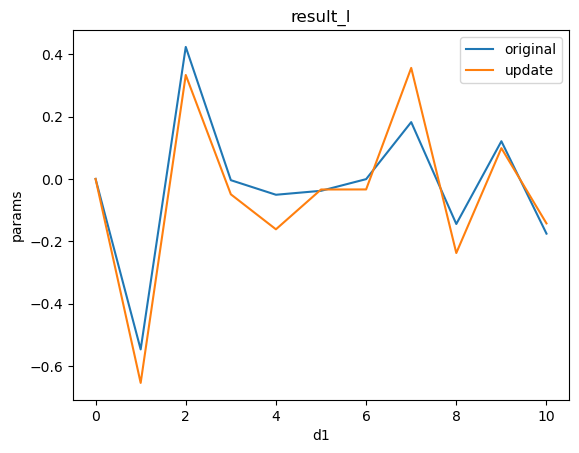

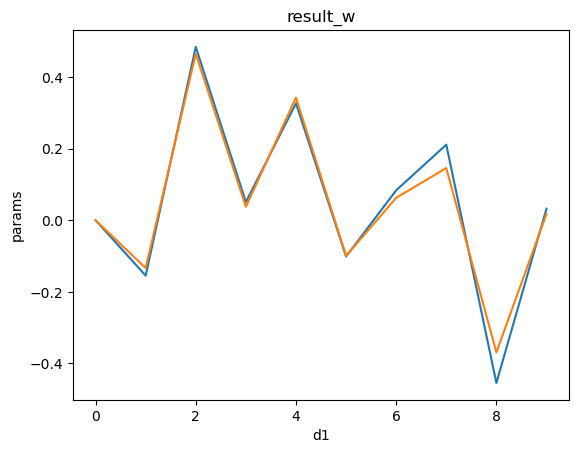

In [ ]:
orig_result_l.params.plot(label = 'original')
update_result_l.params.plot(label = 'update')
plt.legend()
plt.title("result_l")
plt.show()

orig_result_w.params.plot(label = 'original')
update_result_w.params.plot(label = 'update')
plt.title("result_w")
plt.show()


### coefficients

In [ ]:
orig_training_path = 'input/original/'

## these locations will be broken once everything has been checked and looks good
## coefficient_meanstd will now live in ipath with the bt_*.nc files rather than prepath
original_coeff = xr.open_dataset(f'{orig_training_path}coefficient_meanstd.nc').load()
#updated_coeff = xr.open_dataset(orig_training_path+'coefficient_meanstd_update.nc').load()
#updated_coeff_lm = xr.open_dataset(orig_training_path+'coefficient_meanstd_update_lm.nc').load()
# updated_coeff_lm_bt = xr.open_dataset(gv.pre_path+'coefficient_meanstd_update_lm_bt.nc').load()
updated_coeff = xr.open_dataset(gv.ipath+"coefficient_meanstd.nc").load()

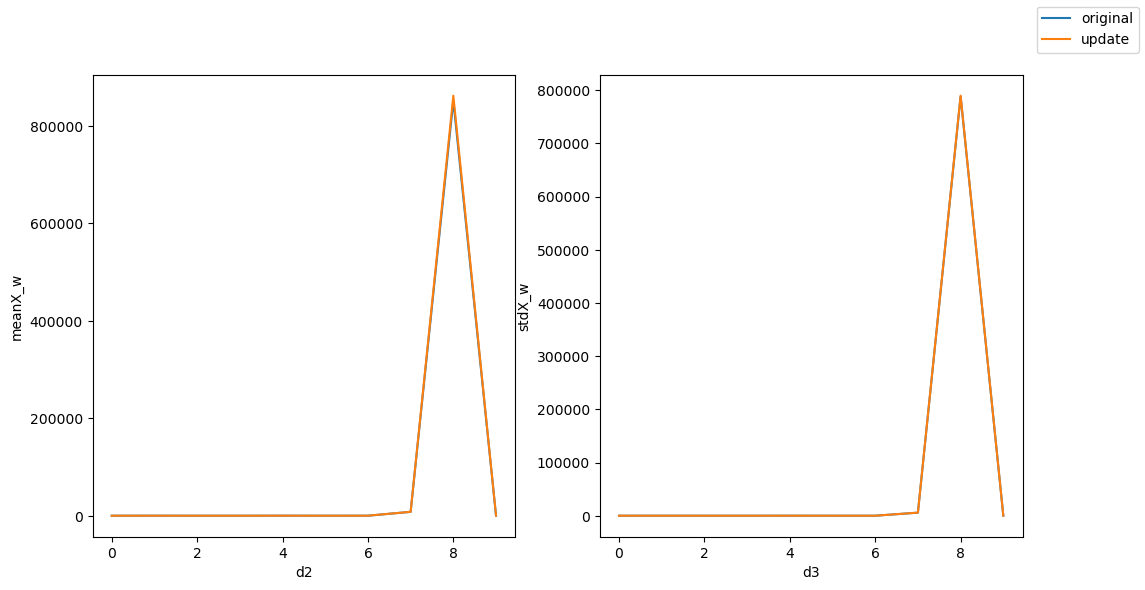

In [ ]:
fig, ax = plt.subplots(ncols = 2, figsize = (12,6))

original_coeff.meanX_w.plot(label = 'original', ax = ax[0])
updated_coeff.meanX_w.plot(label = 'update', ax = ax[0])

original_coeff.stdX_w.plot(ax = ax[1])
updated_coeff.stdX_w.plot(ax = ax[1])

fig.legend()


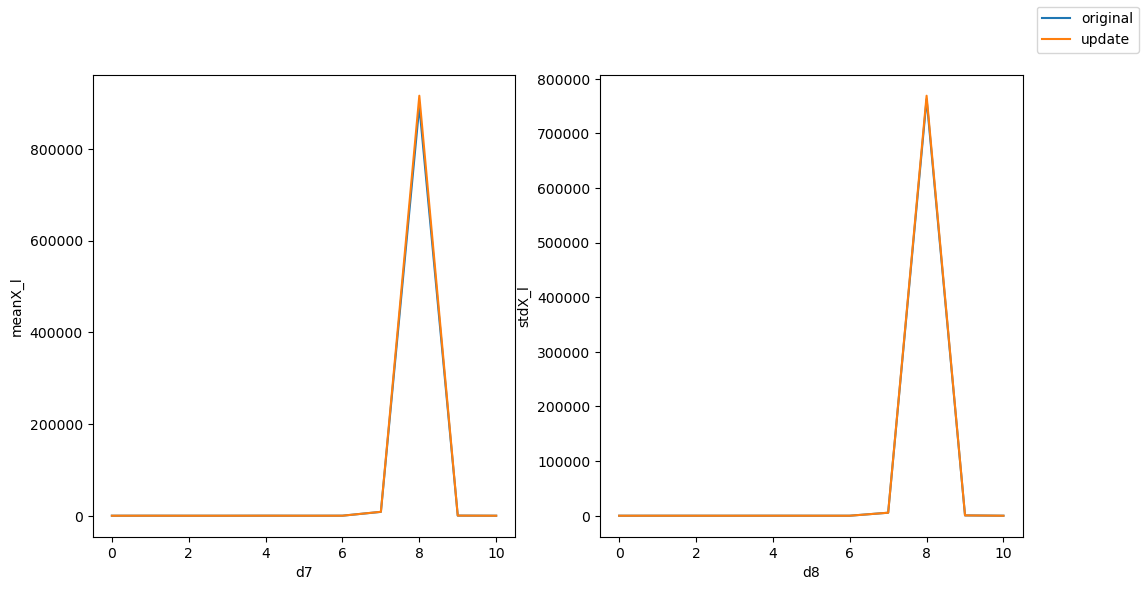

In [ ]:
fig, ax = plt.subplots(ncols = 2, figsize = (12,6))

original_coeff.meanX_l.plot(label = 'original', ax = ax[0])
updated_coeff.meanX_l.plot(label = 'update', ax = ax[0])

original_coeff.stdX_l.plot(ax = ax[1])
updated_coeff.stdX_l.plot(ax = ax[1])

fig.legend()


In [ ]:
original_coeff

In [ ]:
bt_global_original = xr.open_dataset("input/original/bt_global_predictors.nc")
bt_global_update = xr.open_dataset(gv.ipath+"/bt_global_predictors.nc")

### errors

In [ ]:
from scipy.stats import ks_2samp

a = bt_global_update['errors'].values    
b = bt_global_original['errors'].values    

# a = xr.open_dataset('errors_new.nc')['errors'].values.ravel()
# b = xr.open_dataset('errors_old.nc')['errors'].values.ravel()

a, b = a[~np.isnan(a)], b[~np.isnan(b)]

def summarize(e):
    return dict(n=e.size, mean=e.mean(), std=e.std(),
                rmse=np.sqrt((e**2).mean()), mae=np.abs(e).mean(),
                p5=np.percentile(e, 5), p50=np.percentile(e, 50), p95=np.percentile(e, 95))

for name, e in [('new', a), ('old', b)]:
    print(name, {k: round(float(v), 3) for k, v in summarize(e).items()})

print(ks_2samp(a, b))

new {'n': 75946.0, 'mean': 0.0, 'std': 7.702, 'rmse': 7.702, 'mae': 5.464, 'p5': -11.311, 'p50': -0.404, 'p95': 12.472}
old {'n': 79181.0, 'mean': -0.096, 'std': 7.587, 'rmse': 7.587, 'mae': 5.377, 'p5': -12.38, 'p50': 0.322, 'p95': 11.084}
KstestResult(statistic=np.float64(0.049380688526438066), pvalue=np.float64(1.373650882006265e-82), statistic_location=np.float64(0.17618630823440767), statistic_sign=np.int8(1))


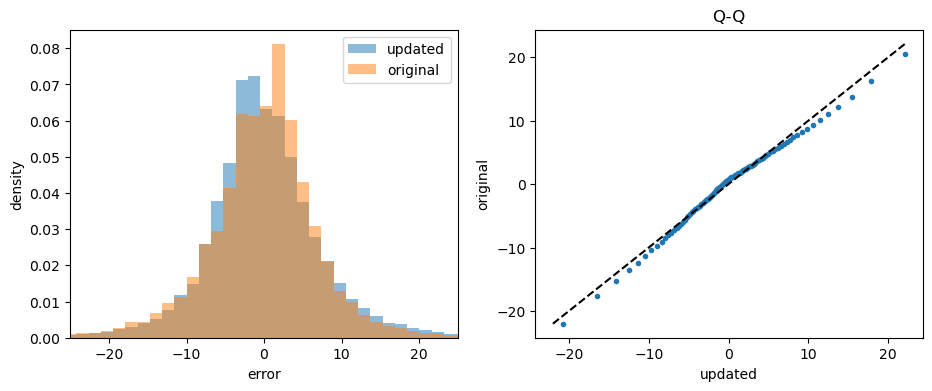

In [ ]:
import matplotlib.pyplot as plt


fig, ax = plt.subplots(1, 2, figsize=(11, 4))

bins = np.linspace(min(a.min(), b.min()), max(a.max(), b.max()), 100)
ax[0].hist(a, bins, density=True, alpha=0.5, label='updated')
ax[0].hist(b, bins, density=True, alpha=0.5, label='original')
ax[0].set(xlabel='error', ylabel='density'); ax[0].legend()
ax[0].set_xlim(-25, 25)

q = np.linspace(0.01, 0.99, 99)
qa, qb = np.quantile(a, q), np.quantile(b, q)
ax[1].plot(qa, qb, '.')
lim = [min(qa.min(), qb.min()), max(qa.max(), qb.max())]
ax[1].plot(lim, lim, 'k--')
ax[1].set(xlabel='updated', ylabel='original', title='Q-Q')
plt.show()

In [ ]:
bt_global_original.load()
bt_global_update.load()

list(bt_global_original.data_vars)

['PIslp',
 'PIslpMean',
 'PIwspd',
 'PIwspdMean',
 'StormId',
 'StormInitMonth',
 'StormLat',
 'StormLon',
 'StormMslp',
 'StormMwspd',
 'StormYear',
 'T100',
 'T100Mean',
 'T200',
 'T200Mean',
 'Time',
 'UShear',
 'UShearMean',
 'VShear',
 'VShearMean',
 'basin',
 'dPIwspd',
 'dPdt',
 'dThetaE',
 'dThetaEMean',
 'dThetaEs',
 'dThetaEsMean',
 'dVdt',
 'div200',
 'div200Mean',
 'errors',
 'landmask',
 'landmaskMean',
 'predictand',
 'predictors',
 'rh',
 'rh500_300',
 'rh500_300Mean',
 'rhMean',
 'trDir',
 'trSpeed',
 'trueY']

In [ ]:
bt_global_update.PIslpMean.min(skipna = True)

<xarray.DataArray 'PIslpMean' ()> Size: 8B
array(nan)

In [ ]:
bt_global_original.PIslpMean.max()

<xarray.DataArray 'PIslpMean' ()> Size: 8B
array(1022.59878082)

**original:**
result_l: 
        array([-2.97505076e-16, -5.46849145e-01,  4.23375647e-01, -4.05607218e-03,
       -5.08180058e-02, -3.81636679e-02, -7.10744064e-04,  1.82160493e-01,
       -1.44586750e-01,  1.20882852e-01, -1.75497913e-01])

result_w: 
        array([ 2.70763230e-15, -1.54747128e-01,  4.84125196e-01,  5.07832262e-02,
        3.26370065e-01, -1.01314388e-01,  8.35413010e-02,  2.11059956e-01,
       -4.54481707e-01,  3.22197594e-02])

**update_2012:**
result_l
        array([ 4.85722573e-17, -6.24211217e-01,  3.31230415e-01, -2.88202887e-03,
       -1.43665689e-01, -5.15718264e-02, -3.27434531e-02,  2.82406886e-01,
       -1.57618307e-01,  9.08907019e-02, -1.47832610e-01])

result_w:
        array([ 4.92803769e-17, -1.40061851e-01,  4.65414369e-01,  1.85616612e-02,
        3.16763829e-01, -9.82187256e-02,  6.77520089e-02,  1.70697446e-01,
       -3.83740688e-01,  1.60916391e-02])

**update_2025:**
result_l:

result_w:

original and update 2012 coefficient match exactly. 

In [ ]:
# ### OTHER TRAINING 


# #!/usr/bin/env python
# # coding: utf-8

# # # Retrain CHAZ intensity with ERA5 data
# # 
# # created by Chia-Ying Lee, cl3225@columbia.edu, July 2025

# # In[2]:


# import numpy as np
# import xarray as xr
# import pandas as pd
# import copy
# import time
# import pickle
# from scipy.io import loadmat
# from netCDF4 import Dataset
# from scipy.io import  netcdf_file
# from datetime import datetime

# import dask.array as da
# from dask.diagnostics import ProgressBar

# import warnings
# warnings.filterwarnings("ignore")


# # In[3]:


# class global_variables():
#     """
#     global variables in Namelist.py in CHAZ
#     """
#     def __init__(self):
#         ## for trainning, we still start from 1981 for after satellite era
#         self.Year1 = 1981 
#         self.Year2 = 2023
#         landmaskfile = '/home/clee/CHAZ/landmask.nc'        
#         f = netcdf_file(landmaskfile)
#         self.lon = f.variables['lon'][::9]
#         self.lat = f.variables['lat'][::9]
#         self.landmask = f.variables['landmask'][::-9,::9]
#         self.ldxxlong,self.ldxxlat = np.meshgrid(self.lon,self.lat)
#         f.close()


# # In[ ]:





# # ## Required functions 
# # - This NB should be stand alone for sharing with community

# # In[4]:


# def int2str(num,l):
#         """
#         Given an integer num and desired length l, returns the str(num)
#         with appended leading zeroes to match the size l.
#         """
#         if len(str(num))<l:
#                 return (l-len(str(num)))*'0'+str(num)
#         else:
#                 return str(num)


# # In[5]:


# class read_ibtracs_v4_addCHAZvariables(object):
#         """
#         a function read /data2/clee/bttracks/IBTrACS.ALL.v04r00.nc
#         netCDF4 library is required
#         we use all USA agency - usa_lat, usa_lon, etc 
#         atl - NHC ATL
#         enp - NHC ENP
#         wnp,sh,ni - JTWC for the rest: SH, IO, and WPC
#         'global', it is reading all data

#         lon is change to the range from 0 to 360

#         to do task: use xarray to have better time calculations
#         data = xr.to_nedcdf(filename)
#         """
#         def __init__(self,ncFileName,basins):
#             #ncFileName = '/data2/clee/bttracks/IBTrACS.ALL.v04r00.nc'
#             ds = xr.open_dataset(ncFileName)
#             sourceN = []
#             if 'atl' in basins:
#                     sourceN.extend(['NA'])
#             if 'wnp' in basins:
#                     sourceN.extend(['WP'])
#             if 'sh' in basins:
#                     sourceN.extend(['SA','SP','SI'])
#             if 'ni' in basins:
#                     sourceN.extend(['NI'])
#             if 'enp' in basins:
#                     sourceN.extend(['EP'])
#             if 'global' in basins:
#                     sourceN = ['NA','WP','SA','SP','SI','NI','EP']
#             sourceN = np.array(sourceN)
#             arg=[]
#             for i in range(sourceN.shape[0]):
#                 arg.extend(np.where(ds.basin[:,0] == sourceN[i].encode("utf-8"))[0].ravel().tolist())
#             arg = np.array(arg)

#             ### get rid of storms with no valid locations and those before 1981.
#             ### this is for CHAZ trainning data, so we use everything after 1981
#             lon = ds.usa_lon.values[arg]
#             lon[lon<0] = lon[lon<0]+360
#             year = ds.season.values[arg]
#             nNaN = np.argwhere((np.nanmax(np.array(lon),axis=1)==np.nanmax(np.array(lon),axis=1)) & (year>=1981) & (year<=2023)).ravel()
#             ds1 = ds.sel(storm=arg[nNaN])
            
#             print ('start to get 6 hourly data')
#             ### only want data every 6 hours
#             hours = ds1.time.dt.hour.values[:,0]
#             hours = ds1.time.dt.hour.values[:,:]
#             hours_index_int = 0*hours+1.0
#             hours_index_int[np.mod(hours,6)!=0]=float('nan')
   
#             ### since this is for CHAZ, we only use data after 1980
#             lon  = ds1.usa_lon.values
#             lon = lon*hours_index_int
#             lat = ds1.usa_lat.values
#             wspd = ds1.usa_wind.values
#             dist2land = ds1.dist2land.values
#             trspeed = ds1.storm_speed.values
#             trdir = ds1.storm_dir.values

            
#             self.StormLon = np.zeros([np.int_(lon.shape[0]),np.int_(lon.shape[1]/2)])+np.float_('NaN')
#             cleaned_lon = [row[~np.isnan(row)] for row in lon]        
#             self.StormLat = np.zeros([np.int_(lon.shape[0]),np.int_(lon.shape[1]/2)])+np.float_('NaN')
#             cleaned_lat = [row[~np.isnan(row)] for row in lat]
#             self.StormMwspd = np.zeros([np.int_(lon.shape[0]),np.int_(lon.shape[1]/2)])+np.float_('NaN')
#             cleaned_wspd = [row[~np.isnan(row1)] for row,row1 in zip(wspd,lon)]
#             self.dist2land = np.zeros([np.int_(lon.shape[0]),np.int_(lon.shape[1]/2)])+np.float_('NaN')
#             cleaned_dist2land = [row[~np.isnan(row1)] for row,row1 in zip(dist2land,lon)]
#             self.trspeed = np.zeros([np.int_(lon.shape[0]),np.int_(lon.shape[1]/2)])+np.float_('NaN')
#             cleaned_trspeed = [row[~np.isnan(row1)] for row,row1 in zip(trspeed,lon)]
#             self.trdir = np.zeros([np.int_(lon.shape[0]),np.int_(lon.shape[1]/2)])+np.float_('NaN')
#             cleaned_trdir = [row[~np.isnan(row1)]for row,row1 in zip(trdir,lon)]
            
#             time1 = pd.to_datetime(ds1.time.values)
#             cleaned_StormYear = [row.year[~np.isnan(row1)] for row,row1 in zip(time1,lon)]  
#             cleaned_StormMonth = [row.month[~np.isnan(row1)] for row,row1 in zip(time1,lon)]
#             cleaned_StormDay = [row.day[~np.isnan(row1)] for row,row1 in zip(time1,lon)]
#             cleaned_StormHour = [row.hour[~np.isnan(row1)] for row,row1 in zip(time1,lon)] 
#             self.Time = np.array(time1)[:,:180]
#             self.StormYear = np.zeros([np.int_(lon.shape[0]),np.int_(lon.shape[1]/2)])+np.float_('NaN')
#             self.StormMonth = np.zeros([np.int_(lon.shape[0]),np.int_(lon.shape[1]/2)])+np.float_('NaN')
#             self.StormDay = np.zeros([np.int_(lon.shape[0]),np.int_(lon.shape[1]/2)])+np.float_('NaN')
#             self.StormHour = np.zeros([np.int_(lon.shape[0]),np.int_(lon.shape[1]/2)])+np.float_('NaN')
            
#             basin = ds1.basin.values
#             cleaned_basin = [row[~np.isnan(row1)] for row,row1 in zip(basin,lon)]
#             self.basin = basin[:,:180]
#             status = ds1.usa_status.values
#             cleaned_status = [row[~np.isnan(row1)] for row,row1 in zip(status,lon)]
#             self.status = status[:,:180]
            
#             for i in np.arange(self.StormLon.shape[0]):
#                 ix = cleaned_lon[i].size
#                 ix = np.nanmin([ix,180])
#                 self.StormLon[i,:ix] = cleaned_lon[i][:ix] 
#                 self.StormLat[i,:ix] = cleaned_lat[i][:ix]
#                 #try:
#                 self.StormMwspd[i,:ix] = cleaned_wspd[i][:ix]
#                 #except Exception as e:
#                 #    print(i,ix,cleaned_wspd[i][:ix])
                      
#                 self.dist2land[i,:ix] = cleaned_dist2land[i][:ix]
#                 self.trspeed[i,:ix] = cleaned_trspeed[i][:ix]
#                 self.trdir[i,:ix] = cleaned_trdir[i][:ix]
#                 self.Time[i,:ix] = time1[i][:ix]
#                 self.Time[i,ix:] = np.full(180-ix, np.datetime64('NaT'), dtype='datetime64[ns]')
#                 self.StormYear[i,:ix] = cleaned_StormYear[i][:ix]
#                 self.StormMonth[i,:ix] = cleaned_StormMonth[i][:ix]
#                 self.StormDay[i,:ix] = cleaned_StormDay[i][:ix]
#                 self.StormHour[i,:ix] = cleaned_StormHour[i][:ix]
#                 self.basin[i,:ix] = cleaned_basin[i][:ix]
#                 self.basin[i,ix:] = np.full(180-ix, b'', dtype=object)
#                 self.status[i,:ix] = cleaned_status[i][:ix]
#                 self.status[i,ix:] = np.full(180-ix, b'', dtype=object)
#             #basin = ds1.basin.values
#             #self.basin = np.array([basin[i,hours_index_int[i]:hours_index_end[i]:2] for i in range(hours.shape[0])])
#             #status = ds1.usa_status.values
#             #self.status = np.array([status[i,hours_index_int[i]:hours_index_end[i]:2] for i in range(hours.shape[0])])

#             self.season = ds1.season.values
#             self.name = ds1.name.values
            
#             ### new variables for CHAZ ###
#             self.PIwspd = np.zeros(self.StormMwspd.shape,dtype=float)*np.float_('Nan')
#             self.PIslp = np.zeros(self.StormMwspd.shape,dtype=float)*np.float_('Nan')
#             self.UShear = np.zeros(self.StormMwspd.shape,dtype=float)*np.float_('Nan')
#             self.VShear = np.zeros(self.StormMwspd.shape,dtype=float)*np.float_('Nan')
#             self.rh = np.zeros(self.StormMwspd.shape,dtype=float)*np.float_('Nan')
#             self.landmask = np.zeros(self.StormMwspd.shape,dtype=float)*np.float_('Nan')
#             self.dVdt = np.zeros(self.StormMwspd.shape,dtype=float)*np.float_('Nan')
#             self.PIwspdMean = np.zeros(self.StormMwspd.shape,dtype=float)*np.float_('Nan')
#             self.PIslpMean = np.zeros(self.StormMwspd.shape,dtype=float)*np.float_('Nan')
#             self.UShearMean = np.zeros(self.StormMwspd.shape,dtype=float)*np.float_('Nan')
#             self.VShearMean = np.zeros(self.StormMwspd.shape,dtype=float)*np.float_('Nan')
#             self.rhMean = np.zeros(self.StormMwspd.shape,dtype=float)*np.float_('Nan')
#             self.landmaskMean = np.zeros(self.StormMwspd.shape,dtype=float)*np.float_('Nan')


# # In[6]:


# def date_interpolation(dateInput,fileInput):
#         """
#         fileInput is a 3-d gloabl fields  with time-axis on the first column, eg. fileInput[it,ix,iy]
#         the function return fields interpolated linearly to date on dateInput.
#         if dateInput.month is December, then it returns Dec. field
#         """
#         if dateInput.day >= 15:
#                 if dateInput.month < 12:
#                         date0 = datetime(dateInput.year,dateInput.month,15,0,0)
#                         date1 = datetime(dateInput.year,dateInput.month+1,15,0,0)
#                         dfdays = (dateInput-date0).days
#                         xp = [0, (date1-date0).days]
#                         ratio = np.interp(dfdays,xp,[0,1])
#                         fileOutput = fileInput[dateInput.month-1,:,:]*(1-ratio)+fileInput[dateInput.month,:,:]*(ratio)
#                 else:
#                         fileOutput= fileInput[dateInput.month-1,:,:]
#         else:
#                 if dateInput.month == 1:
#                         fileOutput= fileInput[dateInput.month-1,:,:]
#                 else:
#                         date0 = datetime(dateInput.year,dateInput.month-1,15,0,0)
#                         date1 = datetime(dateInput.year,dateInput.month,15,0,0)
#                         dfdays = (dateInput-date0).days
#                         xp = [0, (date1-date0).days]
#                         ratio = np.interp(dfdays,xp,[0,1])
#                         fileOutput = fileInput[dateInput.month-2,:,:]*(1-ratio)+fileInput[dateInput.month-1,:,:]*ratio
#         return fileOutput


# # In[7]:


# def get_predictors(iiS,block_id=None):
#     iS = np.int_(iiS.mean(keepdims=True))[0]
#     #print(iS)
#     #def get_predictors(iS,bt):
#     predictors=['StormMwspd','dVdt','trSpeed','dPIwspd','SHRD','rhMean','dPIwspd2','dPIwspd3','dVdt2','landmaskMean']
#     fpath = '/xpt/berimbau.local/data2/clee/ERA5/era5data_20250610/'
    
#     ### v component
#     filename = fpath+'v_component_of_wind_'+int2str(np.int_(bt.StormYear[iS,0]),4)+'.nc'
#     ds = xr.open_dataset(filename)
#     xlong = ds.longitude.values
#     xlat = ds.latitude.values
#     v200 = ds.v.sel(pressure_level=200).values
#     v250 = ds.v.sel(pressure_level=250).values
#     v850 = ds.v.sel(pressure_level=850).values
    
#     ### u component
#     filename = fpath+'u_component_of_wind_'+int2str(np.int_(bt.StormYear[iS,0]),4)+'.nc'
#     ds = xr.open_dataset(filename)
#     u200 = ds.u.sel(pressure_level=200).values
#     u250 = ds.u.sel(pressure_level=250).values
#     u850 = ds.u.sel(pressure_level=850).values
    
#     ### deep-layer mean shear between 200 and 850 
#     u = u250 - u850
#     v = v200 - v850
    
#     ### humidity
#     ### here the humidity data contains data fro 500, 700, and 850 mb
#     filename = fpath+'relative_humidity_'+int2str(np.int_(bt.StormYear[iS,0]),4)+'.nc'
#     ds = xr.open_dataset(filename)
#     hur = np.nanmean(ds.r.values,axis=1)
    
#     ### read PI from Suzana's PI data, it is in the matlabe format
#     #filename = '/xpt/berimbau.local/data1/suzana/ERA5/PotInt/VelMax_PresMin_ERA5_PI_'+f"{np.int_(bt.StormYear[iS,0]):04d}"+'.mat'
#     #       
#     filename = '/xpt/berimbau.local/data1/suzana/ERA5/PotInt/VelMax_PresMin_ERA5_PI_'+int2str(np.int_(bt.StormYear[iS,0]),4)+'.mat'
    
    
#     ds_PI = loadmat(filename)
#     PIVmax = ds_PI['FVmax']*1.94384449 #m/s - kt
#     PIVmax =np.rollaxis(PIVmax,2,0)
    
    
#     xxlong,xxlat = np.meshgrid(xlong,xlat)
    
#     for it in range(0,bt.StormLon[iS,:].shape[0],1):
#         if pd.to_datetime(bt.Time[iS,it]) == pd.to_datetime(bt.Time[iS,it]):
#             distance = np.empty(xxlong.shape,dtype=float)
#             er = 6371.0 #km
#             londis = 2*np.pi*er*np.cos(xxlat/180*np.pi)/360
#             dx = londis*(xxlong - bt.StormLon[iS,it])
#             dy = 110 * (xxlat - bt.StormLat[iS,it])
#             distance = np.sqrt(dx*dx+dy*dy)
#             (j0,i0) = np.unravel_index(np.argmin(distance),distance.shape)

#             var,radius1,radius2 =  date_interpolation(pd.to_datetime(bt.Time[iS,it]),PIVmax),0,500
#             bt.PIwspdMean[iS,it] = np.mean(var[(distance<=radius2) & (distance>=radius1) & (var==var)])
#             bt.PIwspd[iS,it] = var[j0,i0]

#             var,radius1,radius2 =  date_interpolation(pd.to_datetime(bt.Time[iS,it]),u),200,800
#             bt.UShearMean[iS,it] = np.mean(var[(distance<=radius2) & (distance>=radius1) & (var==var)])
#             bt.UShear[iS,it] = var[j0,i0]

#             var,radius1,radius2 =  date_interpolation(pd.to_datetime(bt.Time[iS,it]),v),200,800
#             bt.VShearMean[iS,it] = np.mean(var[(distance<=radius2) & (distance>=radius1) & (var==var)])
#             bt.VShear[iS,it] = var[j0,i0]

#             var,radius1,radius2 =  date_interpolation(pd.to_datetime(bt.Time[iS,it]),hur),200,800
#             bt.rhMean[iS,it] = np.mean(var[(distance<=radius2) & (distance>=radius1) & (var==var)])
#             bt.rh[iS,it] = var[j0,i0]
            
#             if it >=2 :
#                 bt.dVdt[iS,it] = bt.StormMwspd[iS,it] - bt.StormMwspd[iS,it-2] #( every 12h )

#             del var
#             var,radius1,radius2 = copy.copy(gv.landmask),0,300
#             var[var==0] = -1.
#             var[var==3] = 0.0
#             ### recalculating the ix,iy landmask ####
#             distance = np.empty(gv.ldxxlong.shape,dtype=float)
#             londis = 2*np.pi*er*np.cos(gv.ldxxlat/180*np.pi)/360
#             dx = londis*(gv.ldxxlong - bt.StormLon[iS,it])
#             dy = 110 * (gv.ldxxlat - bt.StormLat[iS,it])
#             distance = np.sqrt(dx*dx+dy*dy)
#             (j0,i0) = np.unravel_index(np.argmin(distance),distance.shape)
#             ###########################################
#             bt.landmaskMean[iS,it] = np.mean(var[(distance<=radius2) & (distance>=radius1) & (var==var)])
#             bt.landmask[iS,it] = var[j0,i0]

#     return iS


# # ## Start the calculation

# # In[8]:


# ## Calculating Predictors
# global bt
# bt = read_ibtracs_v4_addCHAZvariables('/xpt/berimbau.local/data2/clee/bttracks/IBTrACS.ALL.v04r01.nc','global')
# gv = global_variables()


# # In[ ]:


# #for parallell processing, but it is still kind slow.... 
# diS = da.from_array(np.arange(0,bt.StormLon.shape[0],1).astype(dtype=np.int32),chunks=(1,))
# #diS = da.from_array(np.arange(0,100,1).astype(dtype=np.int32),chunks=(1,))
# time1 = time.time()
# new = da.map_blocks(get_predictors,diS,chunks=(1,), dtype=diS.dtype)
# with ProgressBar():
#         a = new.compute(scheduler='synchronous',num_workers=10)
# print(time.time()-time1)


# # In[9]:


# #time1 = time.time()
# #for iS in np.arange(0,100,1):
# #      get_predictors(np.array([iS,iS]))
# #print(time.time()-time1)


# # In[ ]:


# with open ('bt_ERA5_CHAZpredictor01.pik','wb') as f:
#         pickle.dump(bt,f)
# f.close()


# # ## Save data to netcdf

# # In[ ]:


# maxCol = bt.PIslp.shape[0]
# ds = xr.Dataset(
#     data_vars={"StormLon": (("stormID", "timestep"), bt.StormLon,
#                      {"long_name": "Longitude", "units": "degree"}),
#               "StormLat":(("stormID", "timestep"), bt.StormLat,
#                      {"long_name": "Latitude", "units": "degree"}),
#                "StormMwspd":(("stormID", "timestep"), bt.StormMwspd,
#                      {"long_name": "Latitude", "units": "kts"}),
#                "dist2land":(("stormID", "timestep"), bt.dist2land,
#                      {"long_name": "Latitude", "units": "km"}),
#                "trspeed":(("stormID", "timestep"), bt.trspeed,
#                      {"long_name": "Latitude", "units": "kts"}),
#                "trdir":(("stormID", "timestep"), bt.trdir,
#                      {"long_name": "Latitude", "units": "degree"}),
#                "StormYear":(("stormID", "timestep"), bt.StormYear,
#                      {"long_name": "Latitude"}),
#                "StormMonth":(("stormID", "timestep"), bt.StormMonth,
#                      {"long_name": "Latitude"}),
#                "StormDay":(("stormID", "timestep"), bt.StormDay,
#                      {"long_name": "Latitude"}),
#                "StormHour":(("stormID", "timestep"), bt.StormHour,
#                      {"long_name": "Latitude"}),               
#                "basin":(("stormID", "timestep"), bt.basin,
#                      {"long_name": "Latitude"}),               
#                "status":(("stormID", "timestep"), bt.status,
#                      {"long_name": "Latitude"}),
#                "PIwspd":(("stormID", "timestep"), bt.PIwspd,
#                      {"long_name": "Latitude", "units": "ms-1"}),
#                "PIslp":(("stormID", "timestep"), bt.PIslp,
#                      {"long_name": "Latitude", "units": "hPa"}),
#                "UShear":(("stormID", "timestep"), bt.UShear,
#                      {"long_name": "Latitude", "units": "ms-1"}),
#                "VShear":(("stormID", "timestep"), bt.VShear,
#                      {"long_name": "Latitude", "units": "ms-1"}),
#                "rh":(("stormID", "timestep"), bt.rh,
#                      {"long_name": "Latitude"}),
#                "landmask":(("stormID", "timestep"), bt.landmask,
#                      {"long_name": "Latitude"}),
#                "dVdt":(("stormID", "timestep"), bt.dVdt,
#                      {"long_name": "Latitude", "units": "kt"}),               
#                "PIwspdMean":(("stormID", "timestep"), bt.PIwspdMean,
#                      {"long_name": "Latitude", "units": "ms-1"}),
#                "PIslpMean":(("stormID", "timestep"), bt.PIslpMean,
#                      {"long_name": "Latitude", "units": "hPa"}),
#                "UShearMean":(("stormID", "timestep"), bt.UShearMean,
#                      {"long_name": "Latitude", "units": "ms-1"}),
#                "VShearMean":(("stormID", "timestep"), bt.VShearMean,
#                      {"long_name": "Latitude", "units": "ms-1"}),
#                "rhMean":(("stormID", "timestep"), bt.rhMean,
#                      {"long_name": "Latitude"}), 
#                "landmaskMean":(("stormID", "timestep"), bt.landmaskMean,
#                      {"long_name": "Latitude"}),
#                "Time":(("stormID", "timestep"), bt.Time,{"long_name": "Time"})},
#     coords={"stormID":("stormID", np.arange(maxCol)),
#            "timestep":("timestep",np.arange(180))},
#     )


# # In[ ]:


# ds.to_netcdf('bt_ERA5_CHAZpredictor01.nc')


# # In[1]:


# ds.Time


# # In[ ]:


# ds1 = xr.open_dataset('/xpt/berimbau.local/data2/clee/bttracks/IBTrACS.ALL.v04r01.nc')


# # In[29]:


# ds1.storm_dir


# # In[ ]:




